# Mefpp ZP Calibration

This notebook will calibrate the swarped frame created in previous steps, so the units of the image will be in erg/s/cm$^2$/arcsec$^2$ instead of e-/s. To achieve that, the notebook will download photometry of the observed field from either SDSS (astroquery.SDSS) or Skymapper (https://skymapper.anu.edu.au/) to compare and calculate the conversion factor required to obtained the desired physical units. <br>
From the final product one should be able to obtain AB magnitudes of the stars directly from the frame.


## About the filters
Skymapper uses filters slightly different with respect the Sloan filters used in OmegaCam. To achieve a better comversion between both set of filters, the former ones are transformed to Sloan magnitudes using the color conversion published in SkyMapper DR1 paper, Fig 17 (https://ui.adsabs.harvard.edu/abs/2018PASA...35...10W/abstract).<br>
A table with different colors for different bandpasses is publicly available at https://skymapper.anu.edu.au/filter-transformations/, which could be use instead of the transformation from the plots (not implemented in the current version).

In the case of the NB659 filter, the calibration is based on the color-color relation for r-i and r-NB published in the VPHASp paper published by Drew et al, 2014, Table 4 (https://ui.adsabs.harvard.edu/abs/2014MNRAS.440.2036D/abstract). As VPHAS data is published in Vega system, the color-color relation was corrected with the zero points for the respective filters so it will be in AB system during the calibration process.


## About the calibration process

The calibration process is governed by the ZPCalibration class found in zp_calibration.py file. The flow of the class is as follow:

- Check for the parents image to get the airmass and gain of each one. This information will be inherited by the calibrated frame.
### SDSS Calibration
- Download data from SDSS DR17 using the astroquery.SDSS class to query the STAR tables.
### Skymapper calibration
- Download the data from Skymapper with a cone search centered at the position defined by the CRVAL headers of the frame and a radius of 0.7 degrees. The raw data will be cleaned to keep only the best sources (skymapper flags and nimaflags = 0) and most likely stars (class_star > 0.9). Only the bands sm g, r, i and z will be transformed to SDSS magnitudes and saved in the final (clean) catalogue.
- Perform aperture photometry on the input frame based on the position of the stars from the clean Skymapper catalogue.
- Computes the ZP (in magnitudes) via minimization of the differences in magnitudes m$_\mathrm{sm}$ - m$_\mathrm{raw}$ in the case of the filters g, r, i and z. For NB it minimizes the differences in magnitude m$_\mathrm{r}$ - m$_\mathrm{raw}$ versus m$_\mathrm{r}$ - m$_\mathrm{i}$.
- Computes the conversion factor between e-/s (raw units) and 10**-15 erg/s/cm$^2$/arcsec$^2$ (desired physical units).
- Computes the ZP required to go directly to AB magnitudes from the calibrated frame.
- Update the headers and data of frame fits accordlingly.


## About the check of calibration

Once the calibration process of the frame is finished, the script calls SExtractor to perform photometry on the frame. Sources between Skymapper and SExtractor are cross-matched to compared their magnitudes. Check plots are created to observe how well the calibration went.

In [1]:
import os
import sys
import glob
import logging
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from astropy.visualization import simple_norm
from astropy.coordinates import SkyCoord
from astropy import units as u
from astropy.io import fits
from matplotlib import cm
from zp_calibration import ZPCalibration
from mefpp_astromatic import SExtractor
import pycavi_tools

In [2]:
def run_sextractor_on_frame(image_path, sex_path, rerun=False):
    """
    Run SExtractor on calibrated frame to get a catalogue of stars.

    ##########
    parameters
    
    image_path : str
        The path to the calibrated frame (symbolic link in the Calibration directory)
    sex_path : str
        The path corresponding to the sextractor folder, the logfile will be saved there
    rerun : bool
        If True, SExtractor will be running again on frame, independently if the output catalogue exists.
    """

    if os.path.isfile(image_path[:-5]+".cat") and not rerun:
        logging.info("SExtractor output catalogue already exists. Skipping.")
        return

    image_name = image_path.split('/')[-1]
    image_dir = "/".join(image_path.split("/")[:-2])+'/'
    current_dir = os.getcwd()
    logging.info("Reading headers from {}".format(image_name))
    logging.info("in directory {}".format(image_dir))
    logging.info("CWD: {}".format(current_dir))
    os.chdir(image_dir)
    
    frame_hdr = fits.getheader(image_path)
    catalogue_path = image_path[:-5]+".cat"
    logging.info("catalogue_path: {}".format(catalogue_path))

    config_dict = {
        # catalog
        "CATALOG_NAME": image_name[:-5]+".cat",
        "CATALOG_TYPE": "ASCII_HEAD",
        "PARAMETERS_NAME": "sex_default.param",
        # extraction
        "DETECT_TYPE": "CCD",
        "DETECT_MINAREA": 5,
        "DETECT_THRESH": 1.5,
        "ANALYSIS_THRESH": 1.5,
        "FILTER": "Y",
        "FILTER_NAME": "default.conv",
        "DEBLEND_NTHRESH": 32,
        "DEBLEND_MINCONT": 0.005,
        "CLEAN": "Y",
        "CLEAN_PARAM": 1.0,
        "MASK_TYPE": "CORRECT",
        # photometry
        "PHOT_APERTURES": 20.0,
        "PHOT_AUTOPARAMS":  "2.5, 3.5",
        "PHOT_PETROPARAMS": "2.0, 3.5",
        "SATUR_LEVEL": 50000.0,
        "SATUR_KEY": "SATURATE",
        "MAG_ZEROPOINT": frame_hdr["MEFPP QC MAGZP"],
        "MAG_GAMMA": 4.0,
        "GAIN": 2.6,
        "GAIN_KEY": "GAIN",
        "PIXEL_SCALE": 0,
        # star/galaxy separation
        "SEEING_FWHM": 1.2,
        "STARNNW_NAME": "default.nnw",
        # background
        "BACK_SIZE": 128,
        "BACK_FILTERSIZE": 3,
        "BACKPHOTO_TYPE": "LOCAL",
        # check image
        "CHECKIMAGE_TYPE": "NONE",
        "CHECKIMAGE_NAME": "check.fits",
        # Memory (change with caution!)
        "MEMORY_OBJSTACK": 3000,
        "MEMORY_PIXSTACK": 300000,
        "MEMORY_BUFSIZE": 1024,
        # Miscellaneous
        "VERBOSE_TYPE": "NORMAL",
        "HEADER_SUFFIX": ".head",
        "WRITE_XML": "N",
        "XML_NAME": "sex.xml"
    }

    param_dict = {
        # Star id
        "NUMBER": "Running object number",
        # star ra dec
        "ALPHA_J2000": "Right ascension of barycenter(J2000) [deg]",
        "DELTA_J2000": "Declination of barycenter(J2000)[deg]",
        # flux and mag
        "FLUX_BEST": "Best of FLUX_AUTO and FLUX_ISOCOR[count]",
        "FLUXERR_BEST": "RMS error for BEST flux[count]",
        "MAG_BEST": "Best of MAG_AUTO and MAG_ISOCOR[mag]",
        "MAGERR_BEST": "RMS error for MAG_BEST[mag]",
        # extraction flags
        "FLAGS": "Extraction flags",
        "FWHM_IMAGE": "FWHM assuming a gaussian core[pixel]",
        "ELLIPTICITY": "1 - B_IMAGE / A_IMAGE",
        "CLASS_STAR": "S/G classifier output"
    }

    # sextractor fails if the name of the catalogue is too long.
    # thus, we need to change directory to where the action will
    # be, that is, where the file to extract is. In this case
    # there is a link to it in the Calibration_dir directory.
    # TBD...
    logging.info("running SExtractor on calibrated frame..")
    se = SExtractor(image_path, sex_path, input_param=param_dict, input_config=config_dict)
    se.run_sextractor()
    os.chdir(current_dir)
    logging.info("SExtractor finished successfully.")

    
def plot_calibration_check(query_catalogue, sex_catalogue_path, zp_cal):
    """
    Created 5 different check plots from the SExtractor photometry on the swarped OmegaCam frame.
    * Calibrated magnitudes vs Catalogue magnitudes
    * Catalogue - Calibrated magnitudes vs Catalogue magnitudes.
    * Catalogue - Calibrated magnitudes vs Catalogue colour. This one also check the systematic increase of magnitude
        in function of the distance from the center R.
    * Catalogue - Calibrated magnitudes vs R [distance from center] color coded Catalogue - Calibrated
    * A check image of the field
    
    ##########
    parameters
    
    phot_catalogue : str
        The path to the clean photometric reference catalogue created during the calibration process of the frame.
    sex_catalogue_path : str
        The path to the SExtractor output catalogue with the photometry of the frame.
    zp_cal : ZPCalibration
        The calibration object containing important information regarding the frame.
        
    ######
    output
    
    calibration image:
        A png image named OBJECT_BAND_calibration_check.png containing the aforementioned plots. It is saved on the
        calibration directory.
    
    """

    logging.info("Creating check plots")
    phot_catalogue = pd.read_csv(query_catalogue)
    sex_catalogue = np.loadtxt(sex_catalogue_path)

    # first load the ra, dec and magnitudes from both catalogues.
    ra_skm = phot_catalogue["raj2000"].to_numpy()
    de_skm = phot_catalogue["dej2000"].to_numpy()
    ra_sex = sex_catalogue[:, 1]
    de_sex = sex_catalogue[:, 2]

    # select bands accordingly to frame band
    # if band is NB_659, then construct the scatter plot using r-i and r-Ha
    # in rest of cases uses g-band and band-OCam
    # except in g case where we use band-r and band-OCam
    if zp_cal.band == "NB_659":
        mag_skm = phot_catalogue["r_SDSS"].to_numpy()
        mag_side_skm = phot_catalogue["i_SDSS"].to_numpy()
        mag_skm_band = "r_SDSS"
        mag_side_skm_band = "i_SDSS"
    else:
        mag_skm = phot_catalogue[zp_cal.band].to_numpy()
        mag_skm_band = zp_cal.band
        if zp_cal.band == "g_SDSS":
            mag_side_skm = phot_catalogue["r_SDSS"].to_numpy()
            mag_side_skm_band = "r_SDSS"
        else:
            mag_side_skm = phot_catalogue["g_SDSS"].to_numpy()
            mag_side_skm_band = "g_SDSS"

    logging.info("Reading sextractor catalogue {}".format(sex_catalogue_path))
    mag_sex = sex_catalogue[:, 5]

    # select only sextractor best sources (flags == 0 and class_star > 0.9)
    flags = sex_catalogue[:, 7]
    class_star = sex_catalogue[:, 10]

    # it was flags==0 and class_star >0.3
    sel_best_stars = (flags == 0) & (class_star > 0.3)
    ra_sex = ra_sex[sel_best_stars]
    de_sex = de_sex[sel_best_stars]
    mag_sex = mag_sex[sel_best_stars]
    logging.info("number of valid entries in sex catalogue: {}".format(len(mag_sex)))

    # cross-match the skm and sex catalogues
    c_skm = SkyCoord(ra=ra_skm * u.degree, dec=de_skm * u.degree)
    c_sex = SkyCoord(ra=ra_sex * u.degree, dec=de_sex * u.degree)
    idx, d2d, _ = c_skm.match_to_catalog_sky(c_sex)

    max_sep = 1.0 * u.arcsec
    sep_constraint = d2d < max_sep

    # match the ra and dec positions
    ra_skm = ra_skm[sep_constraint]
    de_skm = de_skm[sep_constraint]
    ra_sex = ra_sex[idx[sep_constraint]]
    de_sex = de_sex[idx[sep_constraint]]

    # now we have matched the catalogues we can compare mag by mag
    mag_skm = mag_skm[sep_constraint]
    mag_side_skm = mag_side_skm[sep_constraint]
    mag_sex = mag_sex[idx[sep_constraint]]

    # we paint with the distance to the center
    rad_dist = np.sqrt((ra_skm - zp_cal.crval1)**2 + (de_skm - zp_cal.crval2)**2)

    data = zp_cal.data
    wcs = zp_cal.wcs

    mag_max = zp_cal.mag_max
    mag_min = zp_cal.mag_min

    # we plot the ocam vs skymapper relation
    fig = plt.figure(figsize=(15.7, 12.1), dpi=120)

    gs = gridspec.GridSpec(nrows=4, ncols=5, wspace=0.0)  # width_ratios=[1,1,1,1,1])
    ax1 = fig.add_subplot(gs[:-2, :-3])
    ax2 = fig.add_subplot(gs[-2, :-3], sharex=ax1)
    ax3 = fig.add_subplot(gs[:-1, -3:])
    ax4 = fig.add_subplot(gs[-1, :-3])
    ax5 = fig.add_subplot(gs[-1, -3:])
    

    # skm versus sextractor
    ax1.scatter(mag_skm, mag_sex,  color='black', s=2)
    ax1.set_xlim(8.0, mag_max+1.0)
    ax1.set_ylim(8.0, mag_max+1.0)
    ax1.set_xlabel("{} Catalogue".format(zp_cal.band))
    ax1.set_ylabel("{} OCam".format(zp_cal.band))
    if zp_cal.band == "NB_659":
        ax1.set_xlabel("r_SDSS Catalogue".format(zp_cal.band))

    # delta zp vs mag
    sigma_res = np.nanstd(mag_sex - mag_skm)
    ax2.scatter(mag_skm, mag_skm - mag_sex,  color='black', s=2)
    ax2.set_ylim(-10.0*sigma_res, 10.0*sigma_res)
    ax2.axhline(0.0, ls=':')
    ax2.axvline(mag_min, ls=':')
    ax2.axvline(mag_max, ls=':')
    ax2.set_xlabel("{} Catalogue".format(zp_cal.band))
    ax2.set_ylabel("{}\nCatalogue - OCam".format(zp_cal.band))
    if zp_cal.band == "NB_659":
        ax2.set_ylabel("{} - {}\nCatalogue - OCam".format(mag_skm_band, zp_cal.band))

    norm = simple_norm(data, 'sqrt', percent=99)
    ax3.imshow(data, norm=norm)
    zp_cal.aperture.to_pixel(wcs).plot(color='white', lw=1)

    plt.setp(ax3.get_xticklabels(), visible=False)
    plt.setp(ax3.get_yticklabels(), visible=False)

    # delta zp vs color
    color = mag_side_skm - mag_skm
    sigma_clip = (color >= np.nanquantile(color, 0.005)) & (color <= np.nanquantile(color, 0.995))
    
    # if band is g_sdss, invert the color to have g-r instead of r-g. Same for NB659 to have r-i instead of i-r
    if zp_cal.band == "g_SDSS" or zp_cal.band == "NB_659":
        color *= -1
    select = (mag_skm > mag_min) & (mag_skm < mag_max)
    #
    plot4 = ax4.scatter(color[select & sigma_clip], mag_skm[select & sigma_clip] - mag_sex[select & sigma_clip],  
                        c=rad_dist[select & sigma_clip], cmap="viridis", s=1)
    p4 = plt.colorbar(plot4, ax=ax4, label="R [deg]")
    ax4.axhline(0.0, ls=':')
    ax4.set_xlim(np.amin(color[select & sigma_clip]), np.amax(color[select & sigma_clip]))
    ax4.set_ylim(np.amin(mag_skm[select & sigma_clip] - mag_sex[select & sigma_clip]), 
                 np.amax(mag_skm[select & sigma_clip] - mag_sex[select & sigma_clip]))
    ax4.set_xlabel("{} - {} Catalogue".format(mag_side_skm_band, mag_skm_band))
    if zp_cal.band == "NB_659" or zp_cal.band == "g_SDSS":
        ax4.set_xlabel("{} - {} Catalogue".format(mag_skm_band, mag_side_skm_band))
    ax4.set_ylabel("{}\nCatalogue - OCam".format(zp_cal.band))
    if zp_cal.band == "NB_659":
        ax4.set_ylabel("{} - {}\nCatalogue - OCam".format(mag_skm_band, zp_cal.band))

    # dmag versus radius
    plot5 = ax5.scatter(rad_dist[select & sigma_clip], mag_skm[select & sigma_clip] - mag_sex[select & sigma_clip],  
                        c=color[select & sigma_clip], cmap="viridis", s=1)
    p5 = plt.colorbar(plot5, ax=ax5, label="{} - {} Skymapper".format(mag_side_skm_band, mag_skm_band))
    ax5.axhline(0.0, ls=':')
    ax5.set_xlim(np.amin(rad_dist[select & sigma_clip]), np.amax(rad_dist[select & sigma_clip]))
    ax5.set_ylim(np.amin(mag_skm[select & sigma_clip] - mag_sex[select & sigma_clip]), 
                 np.amax(mag_skm[select & sigma_clip] - mag_sex[select & sigma_clip]))
    ax5.set_xlabel("R [deg]")
    if zp_cal.band == "NB_659" or zp_cal.band == "g_SDSS":
        ax5.set_ylabel("{} - {} Catalogue".format(mag_skm_band, mag_side_skm_band))
    else:
        ax5.set_ylabel("{}\nCatalogue - OCam".format(zp_cal.band))
    if zp_cal.band == "NB_659":
        ax5.set_ylabel("{} - {}\nCatalogue - OCam".format(mag_skm_band, zp_cal.band))

    plt.tight_layout()
    logging.info("check plots created. Saving figure...")
    figname = zp_cal.calibrationdir + "/" + zp_cal.frame[:-5] + "_calibration_check.png"
    plt.savefig(figname)
    

2024-06-14 19:24:24,786:INFO:Starting to work on frame CP_Pup_081146p060_m352105p0_r_SDSS.coadd.fits
2024-06-14 19:24:24,788:INFO:Folder already exists
2024-06-14 19:24:24,789:INFO:ZPCalibration: init: reading frame
2024-06-14 19:24:24,830:INFO:ZPCalibration: plate_scale:  0.213 (sx:  0.213 - sy:  0.213) arcsec/pix
2024-06-14 19:24:24,831:INFO:ZPCalibration: init: loading wcs info from frame
2024-06-14 19:24:24,845:WARNING:FITSFixedWarning: 'datfix' made the change 'Set DATE-OBS to '2017-03-13T23:17:13.519' from MJD-OBS'.
2024-06-14 19:24:24,846:INFO:get_avg_gain_from_frame: reading original files used by Swarp to determine gains.
2024-06-14 19:24:32,035:INFO:get_avg_gain_from_frame: avg_gain: 2.147812
2024-06-14 19:24:32,036:INFO:get_avg_airmass_from_frame: reading original files used by Swarp to determine airmass.
2024-06-14 19:24:32,041:INFO:Airmass for image OMEGA.2017-03-13T02:40:12.356_pre_wcs.fits : 1.0545
2024-06-14 19:24:32,044:INFO:Airmass for image OMEGA.2017-03-13T02:43:27.

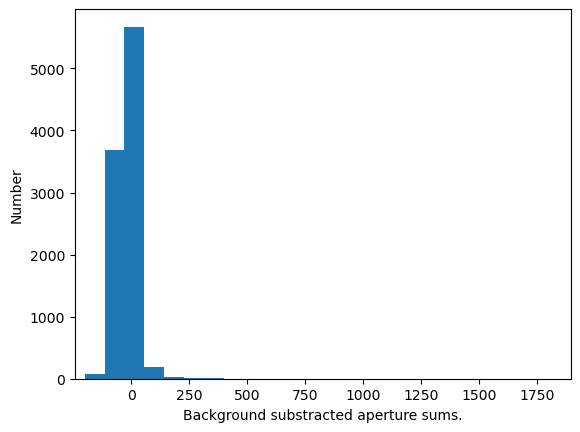

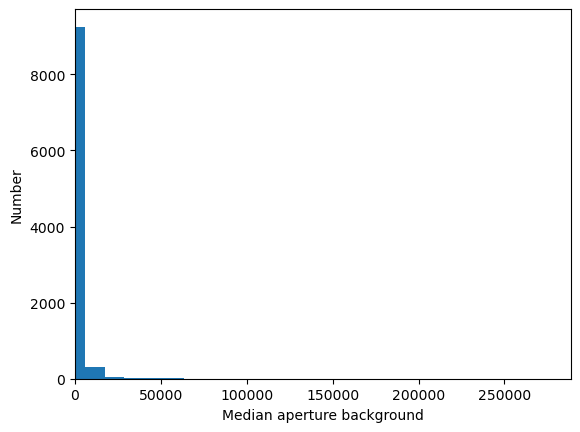

2024-06-14 19:24:38,563:INFO:do_phot: Adding column with raw magnitudes to data frame.
2024-06-14 19:24:38,565:INFO:do_phot: Done.
2024-06-14 19:24:38,694:INFO:df zero point: 25.478
2024-06-14 19:24:38,695:INFO:ZPCalibration: zp: 25.478 to go from ADUs in orig files to mags - ESO health check values
2024-06-14 19:24:38,695:INFO:ZPCalibration: zphc: 25.582 to go from e/s to std mags below atmosphere.
2024-06-14 19:24:38,698:INFO:ZPCalibration: zp2: -21.374 to go from Flambda to std mags above atmosphere.
2024-06-14 19:24:38,699:INFO:ZPCalibration: zp2: -21.374 to go from Flambda to AB mags
2024-06-14 19:24:38,700:INFO:ZPCalibration: zp2: -21.374 (from swarp mosaic DN to AB mags)
2024-06-14 19:24:38,700:INFO:ZPCalibration:               (mosaic DN in erg/s/cm**2)
2024-06-14 19:24:38,701:INFO:get_orig_sky_levels: reading original files used by Swarp to determine sky levels.


2.99792458e+18


2024-06-14 19:24:45,374:INFO:get_orig_sky_levels: sky 1/10: OMEGA.2017-03-13T02:40:12.356_pre_wcs.fits
2024-06-14 19:24:45,375:INFO:get_orig_sky_levels: sky 1/10: 19.758 +- 0.994
2024-06-14 19:24:51,860:INFO:get_orig_sky_levels: sky 2/10: OMEGA.2017-03-13T02:43:27.466_pre_wcs.fits
2024-06-14 19:24:51,860:INFO:get_orig_sky_levels: sky 2/10: 19.877 +- 0.982
2024-06-14 19:24:58,176:INFO:get_orig_sky_levels: sky 3/10: OMEGA.2017-03-13T02:41:17.786_pre_wcs.fits
2024-06-14 19:24:58,177:INFO:get_orig_sky_levels: sky 3/10: 19.780 +- 0.989
2024-06-14 19:25:04,344:INFO:get_orig_sky_levels: sky 4/10: OMEGA.2017-03-13T02:36:57.286_pre_wcs.fits
2024-06-14 19:25:04,345:INFO:get_orig_sky_levels: sky 4/10: 19.616 +- 0.995
2024-06-14 19:25:10,492:INFO:get_orig_sky_levels: sky 5/10: OMEGA.2017-03-13T02:44:33.457_pre_wcs.fits
2024-06-14 19:25:10,492:INFO:get_orig_sky_levels: sky 5/10: 19.911 +- 0.982
2024-06-14 19:25:16,604:INFO:get_orig_sky_levels: sky 6/10: OMEGA.2017-03-13T02:42:22.447_pre_wcs.fits
20

update_frame: before update <data_1d>: 5.207E-02


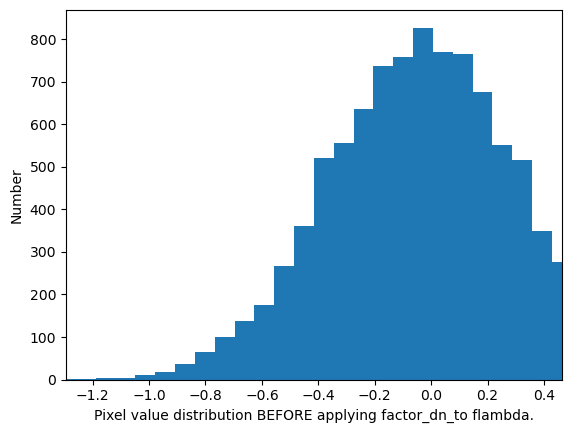

update_frame: before update <data_1d>: 9.459E-21


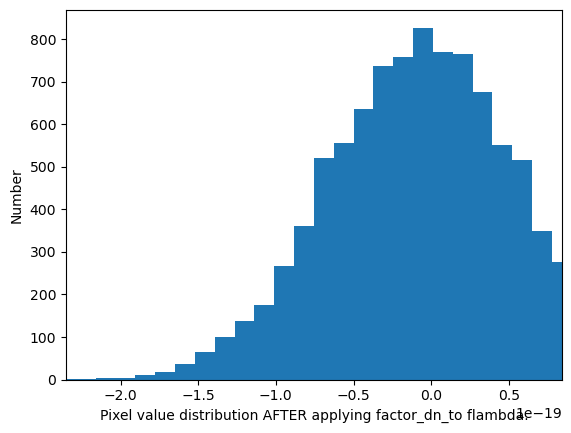

2024-06-14 19:25:51,738:INFO:update_frame: Image updated correctly
2024-06-14 19:25:51,801:INFO:Creating symbolic link to the updated frame
2024-06-14 19:25:51,802:INFO:CP_Pup_081146p060_m352105p0_r_SDSS.coadd.fits -> /Users/fselman/Pictures/OCAM/CPPup2/science//CP_Pup_081146p060_m352105p0/Calibration_dir//CP_Pup_081146p060_m352105p0_r_SDSS.coadd.fits
2024-06-14 19:25:51,806:INFO:ZPCalibration: all done. Celebrate with a cup of coffe :)
2024-06-14 19:25:51,807:INFO:zpcal.calibrationdir: /Users/fselman/Pictures/OCAM/CPPup2/science//CP_Pup_081146p060_m352105p0/Calibration_dir/
2024-06-14 19:25:51,807:INFO:zpcal.frame: CP_Pup_081146p060_m352105p0_r_SDSS.coadd.fits
2024-06-14 19:25:51,809:INFO:Reading headers from CP_Pup_081146p060_m352105p0_r_SDSS.coadd.fits
2024-06-14 19:25:51,810:INFO:in directory /Users/fselman/Pictures/OCAM/CPPup2/science//CP_Pup_081146p060_m352105p0/Swarp_dir/
2024-06-14 19:25:51,811:INFO:CWD: /Users/fselman/Pictures/OCAM/CPPup2/science/CP_Pup_081146p060_m352105p0/Ca

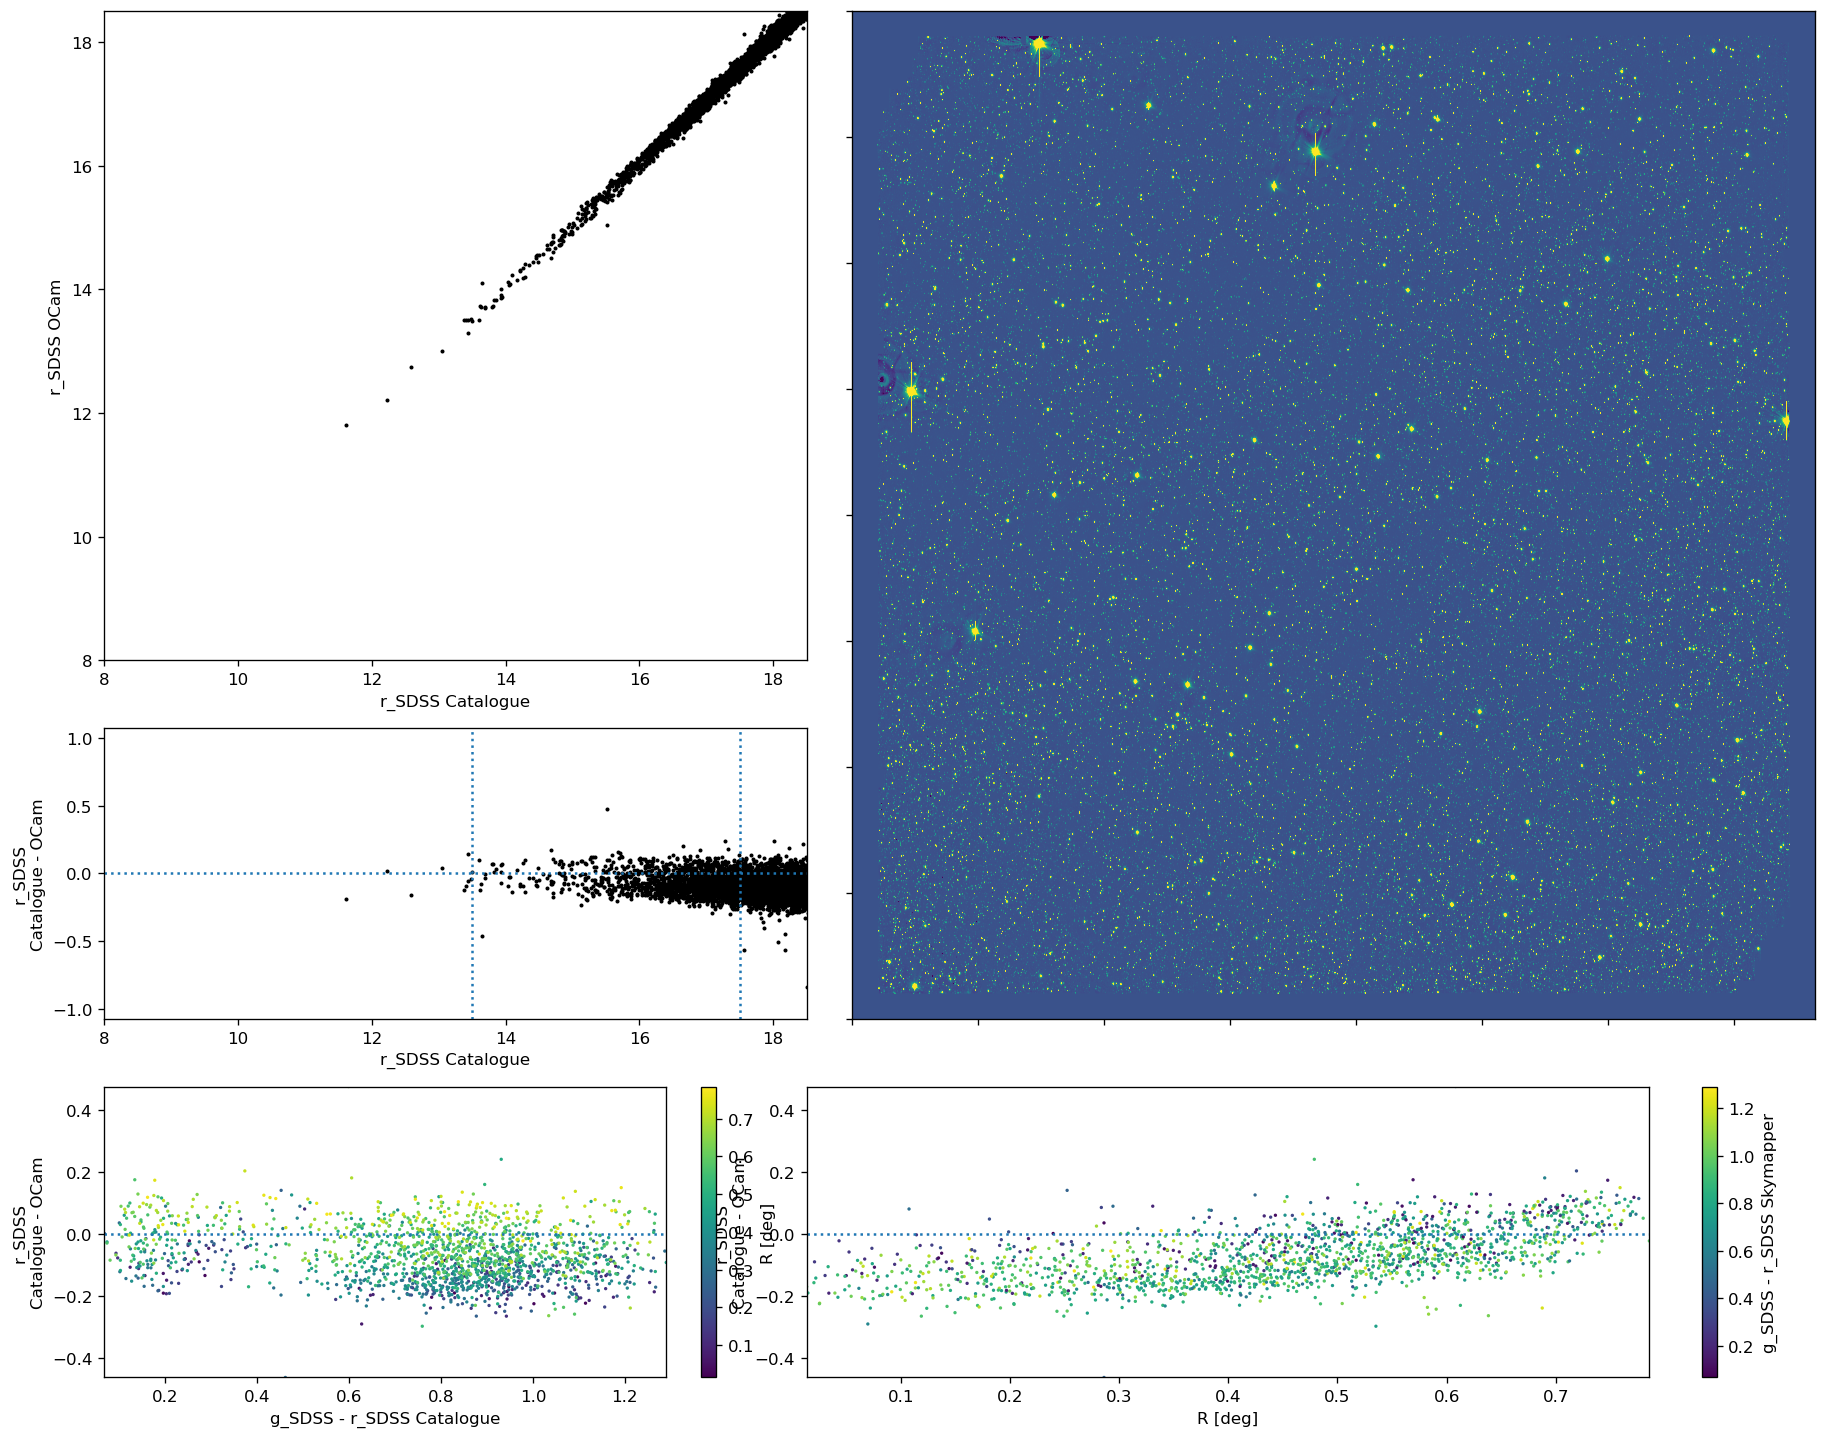

In [3]:
# set the directory folders
config_data = pycavi_tools.read_pycavi_config('./')
observatory = config_data['observatory'] 
project_dir = config_data['project_dir']
reduced_science_dir = config_data['reduced_science_dir']  
log_dir = config_data['project_logs_dir']


# Set the target explicitly. At this point it is believed that
# the data reduction process should be closely monitored, so
# we calibrate target/filter sets one by one.
#
# Eventually the choice of target should be done via GUI
#
target = 'CP_Pup_081146p060_m352105p0'
filter = 'r_SDSS'
sextractor_dir = reduced_science_dir+'/'+target+'/'+config_data['sex_dir_name']+'/'
swarp_dir = reduced_science_dir+'/'+target+'/'+config_data['swarp_dir_name']+'/'
calibration_dir = reduced_science_dir+'/'+target+'/'+config_data['cal_dir_name']+'/'

log_file_swarp = log_dir + "/pymeffpp_swarp.log"
logging.basicConfig(level=logging.INFO,
                    format="%(asctime)s:%(levelname)s:%(message)s",
                    handlers=[
                              logging.FileHandler(log_file_swarp),
                              logging.StreamHandler()])
logging.getLogger().setLevel(logging.INFO)

# We create a list with the names of the registered and combined
# images output by the notebook 6 swarp. 
#
#images_to_calibrate = []
#for image in glob.glob(swarp_dir + "/*.list"):
#    images_to_calibrate.append(image[:-5]+".coadd.fits")
images_to_calibrate = glob.glob(swarp_dir + '/*_'+filter+'.coadd.fits')
images_to_calibrate.sort()

mag_min = 13.5  # minimum magnitude to consider from skymapper catalogue when determining zero point
mag_max = 17.5  # maximum magnitude to consider from skymapper catalogue when determining zero point
aperture_radius = 4.0  # aperture in arcsec when performing aperture photometry on frame 
ap_sky_r1 = 6.0 # annulus inner radius to determine background around stars during aperture photometry
ap_sky_r2 = 9.0 # annulus outer radius to determine background around stars during aperture photometry
query_calibrator = "Skymapper"  # SDSS or Skymapper
query_radius=0.7
query_min_mag=9.0
query_max_mag=19.0

for image in images_to_calibrate:
    
    logging.info("Starting to work on frame {}".format(image.split("/")[-1]))

    # This step queries a photometric database to extract positions and magnitudes
    # to be used to set the zero point of the frame. Currently only skymapper and SDSS
    # are used. Skymapper covers the southern skies and SDSS the northern one.
    #
    zpcal = ZPCalibration(image, swarp_dir, calibration_dir, observatory,
                          mag_min=mag_min, mag_max=mag_max, 
                          ap_radius=aperture_radius, ap_sky_r1=ap_sky_r1, ap_sky_r2=ap_sky_r2,
                          query_calibrator=query_calibrator, 
                          query_radius=query_radius, 
                          query_min_mag=query_min_mag, query_max_mag=query_max_mag)
    logging.info("zpcal.calibrationdir: {}".format(zpcal.calibrationdir))
    os.chdir(zpcal.calibrationdir)

    # Frame has been updated. Now we should use magzp top read magnitudes directly
    # from frame
    logging.info("zpcal.frame: {}".format(zpcal.frame))
    run_sextractor_on_frame(zpcal.swarpdir + "/"+zpcal.frame, swarp_dir)
    
    phot_catalogue = "{0}_query_result_{1}_clean.csv".format(query_calibrator.lower(), zpcal.object)
    logging.info("phot_catalogue_path: {}".format(phot_catalogue))
    sex_catalogue_path = zpcal.swarpdir+zpcal.frame[:-5]+".cat"
    logging.info("sex_catalogue_path: {}".format(sex_catalogue_path))
    plot_calibration_check(phot_catalogue, sex_catalogue_path, zpcal)
    logging.info("Frame {} successfully calibrated".format(zpcal.frame))
    
logging.info("-------Done-------")